# Predicting GitHub user activity

Forecast six types of activity for **Nov. 22 to 29, 2026, Taiwan time**. The model learns from weekly snapshots of the anonymized GH Archive tables. A baseline and two feature ablations test what the temporal and relational features add.

Run the download and the course preprocessing commands in [README.md](README.md) before running this notebook. The Data and Validation sections show the exact period used and which weeks were used for fitting, threshold tuning, and evaluation.

## Setup

Run from the repository root with the kernel that has the packages in `requirements.txt`. Set `STUDENT_ID` below or in the environment to name the checked prediction file.

In [1]:
import json
import os
import re
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from scipy.optimize import minimize
from scipy.special import expit
from threadpoolctl import threadpool_limits

from scripts.evaluate import EVENT_COLS, OUTPUT_COLUMNS, USER_COL, scores
from scripts.preprocess import TABLES

ROOT = Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
TEST_INPUT = ROOT / "submission" / "test_input.csv"
STUDENT_ID = os.environ.get("ASSIGNMENT_STUDENT_ID", "315540018").strip()

TEST_START = pd.Timestamp("2026-11-22 00:00", tz="Asia/Taipei").tz_convert("UTC")
WEEK = pd.Timedelta(days=7)
WINDOWS = (1, 3, 7, 10)
MIN_HISTORY = pd.Timedelta(days=max(WINDOWS))
MIN_COVERAGE = 0.90
N_THREADS = 4

if STUDENT_ID and re.fullmatch(r"[0-9]+", STUDENT_ID) is None:
    raise ValueError("STUDENT_ID must contain digits only.")

required = [DATA / "hours.json", *(DATA / "db" / f"{table}.parquet" for table in TABLES)]
missing = [path.relative_to(ROOT).as_posix() for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Run the README data preparation steps first. Missing: " + ", ".join(missing))

RESULTS.mkdir(exist_ok=True)

## Data and chronological split

The archive end is the last feature cutoff. Every historical fold has the same gap between its feature cutoff and target week as the final forecast. The first folds train the models, the penultimate fold tunes decision thresholds, and the latest complete fold measures performance. The archive coverage check detects missing hour files. It cannot detect missing activity types inside a delivered hour.

In [2]:
manifest = json.loads((DATA / "hours.json").read_text(encoding="utf-8"))
archive_start = pd.Timestamp(manifest["start_utc"])
archive_end = pd.Timestamp(manifest["end_utc_exclusive"])
present_hours = pd.DatetimeIndex(pd.to_datetime(manifest["present_utc"], utc=True)).unique()
deadline = pd.Timestamp("2026-11-21 23:55", tz="Asia/Taipei").tz_convert("UTC")
if not archive_start < archive_end <= deadline or manifest["failed_utc"]:
    raise ValueError("Use a completed historical archive download that ends before the deadline.")
if present_hours.empty or present_hours.min() < archive_start or present_hours.max() >= archive_end:
    raise ValueError("Archive coverage falls outside the interval in hours.json.")

forecast_gap = TEST_START - archive_end

def archive_coverage(start, end):
    observed = ((present_hours >= start) & (present_hours < end)).sum()
    return observed / ((end - start) / pd.Timedelta(hours=1))


def previous_complete_fold(target_end):
    """Find an earlier full label week within the downloaded history."""
    while target_end - WEEK - forecast_gap - MIN_HISTORY >= archive_start:
        target_start = target_end - WEEK
        cutoff = target_start - forecast_gap
        label_coverage = archive_coverage(target_start, target_end)
        history_coverage = archive_coverage(cutoff - MIN_HISTORY, cutoff)
        if target_end <= archive_end and min(label_coverage, history_coverage) >= MIN_COVERAGE:
            return {
                "cutoff": cutoff,
                "target_start": target_start,
                "target_end": target_end,
                "label_hour_coverage": label_coverage,
            }
        target_end -= WEEK
    return None


# Align the held-out week to the official Saturday-UTC / Sunday-Taiwan boundary.
held_out_fold = previous_complete_fold(TEST_START)
tune_fold = previous_complete_fold(held_out_fold["cutoff"]) if held_out_fold else None
train_folds = []
earlier = previous_complete_fold(tune_fold["cutoff"]) if tune_fold else None
while earlier is not None:
    train_folds.append(earlier)
    earlier = previous_complete_fold(earlier["target_start"])

if not train_folds:
    raise ValueError("Need enough history for separate training, tuning, and held-out weeks. Extend the archive start.")
folds = pd.DataFrame([
    *(dict(fold, split="train") for fold in reversed(train_folds)),
    dict(tune_fold, split="tune"),
    dict(held_out_fold, split="held out"),
])
for split in ("tune", "held out"):
    cutoff = folds.loc[folds["split"].eq(split), "cutoff"].iloc[0]
    if folds.loc[folds["cutoff"].lt(cutoff), "target_end"].gt(cutoff).any():
        raise ValueError(f"Earlier labels overlap the {split} feature cutoff.")

print(f"GH Archive (UTC): {archive_start:%Y-%m-%d %H:%M} to {archive_end:%Y-%m-%d %H:%M} (exclusive)")
print(f"Hours available: {len(present_hours):,}  |  Feature-to-target gap: {forecast_gap}")
display(folds)

GH Archive (UTC): 2026-10-03 16:00 to 2026-11-20 15:00 (exclusive)
Hours available: 1,151  |  Feature-to-target gap: 1 days 01:00:00


,cutoff,target_start,target_end,label_hour_coverage,split
0,2026-10-14 13:00:00+00:00,2026-10-15 14:00:00+00:00,2026-10-22 14:00:00+00:00,1.0,train
1,2026-10-21 13:00:00+00:00,2026-10-22 14:00:00+00:00,2026-10-29 14:00:00+00:00,1.0,train
2,2026-10-29 14:00:00+00:00,2026-10-30 15:00:00+00:00,2026-11-06 15:00:00+00:00,1.0,tune
3,2026-11-06 15:00:00+00:00,2026-11-07 16:00:00+00:00,2026-11-14 16:00:00+00:00,1.0,held out


### Load the eight course tables

The stable anonymized user code is the output key. Foreign keys use the row numbers assigned by preprocessing. The cohort list defines the training population, so users without observed events still contribute examples. The time-varying closure, merge, dismissal, name, and owner fields are excluded from the model.

In [3]:
columns = {
    "Users": ["user_id", "github_user_id", "is_cohort", "first_seen_at"],
    "Repositories": ["repo_id", "first_seen_at"],
    "PullRequests": ["pr_id", "author_id", "repo_id", "first_seen_at", "created_at"],
    "Issues": ["issue_id", "author_id", "repo_id", "first_seen_at", "created_at", "is_pull_request"],
    "IssueComments": ["issue_id", "author_id", "repo_id", "created_at", "is_pull_request"],
    "PRReviews": ["pr_id", "reviewer_id", "repo_id", "first_seen_at", "submitted_at"],
    "PRReviewComments": ["pr_id", "author_id", "repo_id", "created_at"],
    "Pushes": ["user_id", "repo_id", "created_at"],
}
tables = {}
for name, fields in columns.items():
    table = pd.read_parquet(DATA / "db" / f"{name}.parquet", columns=fields)
    for field in {"first_seen_at", "created_at", "submitted_at"}.intersection(fields):
        table[field] = pd.to_datetime(table[field], utc=True)
    tables[name] = table

test_users = pd.Index(pd.read_csv(TEST_INPUT, dtype={USER_COL: "int64"})[USER_COL], name=USER_COL)
cohort = pd.Index(
    sorted({int(line) for line in (ROOT / "scripts" / "cohort.txt").read_text().split()}),
    name=USER_COL,
)
if test_users.has_duplicates or not test_users.isin(cohort).all():
    raise ValueError("Expected unique test IDs from the course cohort.")
observed_cohort = tables["Users"].loc[tables["Users"]["is_cohort"], "github_user_id"]
if not observed_cohort.isin(cohort).all():
    raise ValueError("The preprocessed user table does not match the supplied course cohort.")

display(pd.Series({name: len(table) for name, table in tables.items()}, name="Rows").to_frame())
print(f"Cohort: {len(cohort):,} users  |  Official test list: {len(test_users):,} users")

Cohort: 9,000 users  |  Official test list: 4,465 users


,Rows
Users,5680
Repositories,11773
PullRequests,13379
Issues,8489
IssueComments,3206
PRReviews,3301
PRReviewComments,1423
Pushes,35276


### Identify events and targets

Feature time comes from the schema's row-time column. A target requires both a matching row in the target week and an action timestamp in that week. For example, an old issue first seen through a later comment contributes observed history but does not count as a new opening. A review first seen through dismissal counts only when the recorded submission also falls inside the label week. Missing GH Archive events can still hide activity.

In [4]:
activity_specs = {
    "open_pr": ("PullRequests", "author_id", "first_seen_at", "created_at"),
    "open_issue": ("Issues", "author_id", "first_seen_at", "created_at"),
    "issue_comment": ("IssueComments", "author_id", "created_at", "created_at"),
    "pr_review": ("PRReviews", "reviewer_id", "first_seen_at", "submitted_at"),
    "pr_review_comment": ("PRReviewComments", "author_id", "created_at", "created_at"),
    "push": ("Pushes", "user_id", "created_at", "created_at"),
}
users_by_key = tables["Users"].set_index("user_id")
user_codes = users_by_key["github_user_id"]
user_times = users_by_key["first_seen_at"]

def build_activity():
    blocks = []
    for activity, (table_name, actor, row_time, action_time) in activity_specs.items():
        source = tables[table_name]
        if activity == "open_issue":
            source = source.loc[source["is_pull_request"].eq(False)]
        block = pd.DataFrame({
            USER_COL: source[actor].map(user_codes),
            "repo_id": source["repo_id"],
            "row_at": source[row_time],
            "action_at": source[action_time],
            "user_seen_at": source[actor].map(user_times),
            "activity": activity,
        })
        blocks.append(block.loc[block[USER_COL].isin(cohort)].dropna(subset=["row_at"]))
    events = pd.concat(blocks, ignore_index=True)
    events[USER_COL] = events[USER_COL].astype("int64")
    events["activity"] = pd.Categorical(events["activity"], categories=EVENT_COLS)
    events["known_at"] = events["row_at"].where(
        events["row_at"].ge(events["user_seen_at"]), events["user_seen_at"]
    )
    return events


def weekly_targets(start, end, user_index):
    observed = activity.loc[
        activity["row_at"].ge(start) & activity["known_at"].lt(end)
        & activity["action_at"].ge(start) & activity["action_at"].lt(end)
    ]
    return activity_counts(observed, user_index).gt(0).astype("int8")


def activity_counts(events, user_index):
    counts = events.groupby([USER_COL, "activity"], observed=True).size().unstack(fill_value=0)
    return counts.reindex(index=user_index, columns=EVENT_COLS, fill_value=0)


activity = build_activity()
display(activity["activity"].value_counts(sort=False).rename("Observed rows").to_frame())

,Observed rows
activity,
open_pr,4295
open_issue,5402
issue_comment,3206
pr_review,3241
pr_review_comment,1423
push,35276


## Features

- **7-day counts** summarize the six observed activities during the previous week.
- **Temporal** adds 1-, 3-, and 10-day counts, active days, time since the last event, and the change in daily activity between the last three days and the preceding four days.
- **Temporal + relational** adds the repositories reached through activity foreign keys, cohort activity in those repositories, and comments or reviews received via the issue and pull request relationships. Both sides of a join must be observable before the forecast cutoff.

In [5]:
def lookback(events, cutoff, days):
    start = max(cutoff - pd.Timedelta(days=days), archive_start)
    return events.loc[events["row_at"].ge(start) & events["known_at"].lt(cutoff)]


def temporal_features(cutoff, user_index):
    recent = lookback(activity, cutoff, max(WINDOWS))
    blocks = []
    counts_by_window = {}
    for days in WINDOWS:
        window = lookback(recent, cutoff, days)
        counts = activity_counts(window, user_index)
        counts_by_window[days] = counts
        blocks.append(counts.add_prefix(f"count_{days}d_"))

    last_event = recent.groupby([USER_COL, "activity"], observed=True)["row_at"].max().unstack()
    last_event = last_event.reindex(index=user_index, columns=EVENT_COLS)
    recency = last_event.apply(lambda times: (cutoff - pd.to_datetime(times, utc=True)).dt.total_seconds() / 86400)
    recency = recency.fillna(max(WINDOWS) + 1)
    recent_days = (
        recent.assign(day=recent["row_at"].dt.floor("D"))
        .groupby([USER_COL, "activity"], observed=True)["day"].nunique().unstack(fill_value=0)
        .reindex(index=user_index, columns=EVENT_COLS, fill_value=0)
    )
    earlier_four_days = counts_by_window[7] - counts_by_window[3]
    momentum = np.log1p(counts_by_window[3] / 3) - np.log1p(earlier_four_days / 4)
    combined = pd.concat([
        *blocks,
        recency.add_prefix("recency_days_"),
        recent_days.add_prefix("active_days_10d_"),
        momentum.add_prefix("recent_rate_change_"),
    ], axis=1)
    combined["any_activity_days_10d"] = (
        recent.assign(day=recent["row_at"].dt.floor("D"))
        .groupby(USER_COL)["day"].nunique().reindex(user_index, fill_value=0)
    )
    return combined.astype("float32")

In [6]:
def received_activity(table_name, key, object_table, actor, time_field):
    """Join each comment or review to the author of the referenced issue or PR."""
    source = tables[table_name][[key, actor, time_field]].rename(
        columns={actor: "actor_id", time_field: "row_at"}
    )
    objects = tables[object_table][[key, "author_id", "first_seen_at"]].rename(
        columns={"first_seen_at": "object_seen_at"}
    )
    links = source.dropna(subset=[key, "actor_id", "row_at"]).merge(
        objects.dropna(subset=["author_id"]), on=key, validate="many_to_one"
    )
    links[USER_COL] = links["author_id"].map(user_codes)
    links = links.loc[links[USER_COL].isin(cohort) & links["actor_id"].ne(links["author_id"])].copy()
    links["known_at"] = pd.concat([
        links["row_at"],
        links["object_seen_at"],
        links["actor_id"].map(user_times),
        links["author_id"].map(user_times),
    ], axis=1).max(axis=1)
    return links[[USER_COL, "actor_id", "row_at", "known_at"]]


repository_times = tables["Repositories"].set_index("repo_id")["first_seen_at"]
activity["repo_seen_at"] = activity["repo_id"].map(repository_times)
received = {
    "issue_comment": received_activity("IssueComments", "issue_id", "Issues", "author_id", "created_at"),
    "pr_review": received_activity("PRReviews", "pr_id", "PullRequests", "reviewer_id", "first_seen_at"),
    "pr_review_comment": received_activity(
        "PRReviewComments", "pr_id", "PullRequests", "author_id", "created_at"
    ),
}


def relational_features(cutoff, user_index):
    features = pd.DataFrame(index=user_index)
    for days in (7, 10):
        recent = lookback(activity, cutoff, days)
        recent = recent.loc[recent["repo_seen_at"].lt(cutoff)]
        by_user_repo = recent.groupby([USER_COL, "repo_id"]).size().rename("own_events")
        repo_totals = by_user_repo.groupby(level="repo_id").agg(["sum", "size"])
        context = by_user_repo.to_frame().join(repo_totals, on="repo_id")
        context["peer_events"] = context["sum"] - context["own_events"]
        context["peer_users"] = context["size"] - 1
        context["shared"] = context["peer_users"].gt(0)
        by_user = context.groupby(level=USER_COL)
        aggregated = by_user.agg(
            repos=("own_events", "size"),
            shared_repos=("shared", "sum"),
            max_repo_peer_events=("peer_events", "max"),
            max_repo_peer_users=("peer_users", "max"),
            dominant_repo_events=("own_events", "max"),
            repo_events=("own_events", "sum"),
        )
        aggregated["dominant_repo_share"] = aggregated.pop("dominant_repo_events") / aggregated.pop("repo_events")
        for name in aggregated:
            features[f"{name}_{days}d"] = aggregated[name]

        for name, links in received.items():
            contact = lookback(links, cutoff, days).groupby(USER_COL)
            features[f"received_{name}_{days}d"] = contact.size()
            features[f"received_{name}_unique_people_{days}d"] = contact["actor_id"].nunique()
    return features.fillna(0).astype("float32")


def snapshot(cutoff, user_index):
    temporal = temporal_features(cutoff, user_index)
    features = temporal.join(relational_features(cutoff, user_index))
    return features

### Build historical examples

For each fold, the feature snapshot uses only rows available before its cutoff. The next label window supplies one binary target per activity. Activity totals below help identify a week where a target is particularly sparse.

In [7]:
feature_weeks = []
label_weeks = []
for fold in folds.itertuples():
    feature_weeks.append(snapshot(fold.cutoff, cohort))
    label_weeks.append(weekly_targets(fold.target_start, fold.target_end, cohort))

labels_by_week = pd.DataFrame([labels.sum() for labels in label_weeks])
labels_by_week.index = pd.Index(folds["target_start"], name="Target start (UTC)")
display(labels_by_week)
unsupported_training = labels_by_week.loc[folds.loc[folds['split'].eq('train'), 'target_start']].sum().eq(0)
if unsupported_training.any():
    print('No training positives for ' + ', '.join(unsupported_training.index[unsupported_training]) + '.')
print(f"{len(feature_weeks[0].columns)} features across the temporal and relational blocks.")

65 features across the temporal and relational blocks.


activity,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
Target start (UTC),,,,,,
2026-10-15 14:00:00+00:00,394,249,228,258,197,1765
2026-10-22 14:00:00+00:00,308,177,210,202,99,1134
2026-10-30 15:00:00+00:00,383,198,258,276,109,283
2026-11-07 16:00:00+00:00,338,182,205,233,69,277


## Train six classifiers

Each configuration fits one L2-regularized logistic regression per activity. A signed log transform compresses large counts, and centering and scaling are fitted on the training folds. The decision thresholds are fitted on the tuning week to maximize the official average of macro-F1 and micro-F1. The held-out labels stay out of both steps. **Copy last week** uses the same label definitions over the seven days before the feature cutoff.

In [8]:
def log_features(features):
    values = features.to_numpy(dtype="float64")
    return np.sign(values) * np.log1p(np.abs(values))


def add_intercept(values, center, scale):
    return np.column_stack([np.ones(len(values)), (values - center) / scale])


def logistic_objective(coefficients, design, target, penalty):
    logits = design @ coefficients
    slopes = coefficients[1:]
    loss = np.mean(np.logaddexp(0, logits) - target * logits) + 0.5 * penalty * (slopes @ slopes)
    gradient = design.T @ (expit(logits) - target) / len(target)
    gradient[1:] += penalty * slopes
    return loss, gradient


def fit_models(features, labels):
    if not features.index.equals(labels.index):
        raise ValueError("Training features and labels must have the same index.")
    values = log_features(features)
    center = values.mean(axis=0)
    scale = np.maximum(values.std(axis=0), 0.1)
    design = add_intercept(values, center, scale)
    coefficients = {}
    with threadpool_limits(limits=N_THREADS):
        for event in EVENT_COLS:
            target = labels[event].to_numpy(dtype="float64")
            rate = target.mean()
            if rate in (0, 1):
                coefficients[event] = float(rate)
                continue
            initial = np.zeros(design.shape[1])
            initial[0] = np.log(rate / (1 - rate))
            fit = minimize(
                logistic_objective, initial, args=(design, target, 0.005),
                method="L-BFGS-B", jac=True, options={"maxiter": 250, "gtol": 1e-7},
            )
            if not fit.success:
                raise RuntimeError(f"Logistic fit failed for {event}: {fit.message}")
            coefficients[event] = fit.x
    return center, scale, coefficients


def predict_probabilities(models, features):
    center, scale, coefficients = models
    design = add_intercept(log_features(features), center, scale)
    probabilities = {}
    with threadpool_limits(limits=N_THREADS):
        for event, weights in coefficients.items():
            probabilities[event] = weights if isinstance(weights, float) else expit(design @ weights)
    return pd.DataFrame(probabilities, index=features.index)


def tune_thresholds(probabilities, labels):
    """Coordinate search using the course macro/micro score and observed probability ranks."""
    y = labels[EVENT_COLS].to_numpy(dtype=bool)
    p = probabilities[EVENT_COLS].to_numpy()
    ranks = np.r_[np.linspace(0, 0.9, 41), np.linspace(0.901, 1, 100)]
    candidates = [
        np.unique(np.r_[np.quantile(column, ranks), 0.5, np.inf])
        for column in p.T
    ]
    thresholds = np.full(len(EVENT_COLS), 0.5)
    decisions = p >= thresholds
    tp = (decisions & y).sum(axis=0)
    predicted = decisions.sum(axis=0)
    positives = y.sum(axis=0)

    def f1_from_counts(hit, count, actual):
        denom = count + actual
        return np.divide(2 * hit, denom, out=np.ones_like(denom, dtype=float), where=denom > 0)

    for _ in range(4):
        for j, values in enumerate(candidates):
            trial = p[:, j, None] >= values
            trial_hits = (trial & y[:, j, None]).sum(axis=0)
            trial_counts = trial.sum(axis=0)
            activity_f1 = f1_from_counts(trial_hits, trial_counts, positives[j])
            other_f1 = f1_from_counts(tp, predicted, positives).sum()
            other_f1 -= f1_from_counts(tp[j], predicted[j], positives[j])
            micro_f1 = f1_from_counts(
                tp.sum() - tp[j] + trial_hits,
                predicted.sum() - predicted[j] + trial_counts,
                positives.sum(),
            )
            combined = ((other_f1 + activity_f1) / len(EVENT_COLS) + micro_f1) / 2
            best = np.flatnonzero(combined == combined.max())[-1]
            thresholds[j], tp[j], predicted[j] = values[best], trial_hits[best], trial_counts[best]

    return pd.Series(thresholds, index=EVENT_COLS, name="Decision threshold")


def classify(probabilities, thresholds):
    return probabilities.ge(thresholds, axis="columns").astype("int8")


def as_submission(binary):
    return binary[EVENT_COLS].rename_axis(USER_COL).reset_index()[OUTPUT_COLUMNS]

In [9]:
train_indices = folds.index[folds["split"].eq("train")].tolist()
tune_index = folds.index[folds["split"].eq("tune")].item()
held_out_index = folds.index[folds["split"].eq("held out")].item()
training_features = pd.concat([feature_weeks[i] for i in train_indices], keys=train_indices)
training_labels = pd.concat([label_weeks[i] for i in train_indices], keys=train_indices)
tuning_features = feature_weeks[tune_index]
held_out_features = feature_weeks[held_out_index]
tuning_labels = label_weeks[tune_index]
held_out_truth = as_submission(label_weeks[held_out_index])

feature_sets = {
    "7-day counts": training_features.filter(regex="^count_7d_").columns,
    "Temporal": temporal_features(folds.loc[tune_index, "cutoff"], cohort).columns,
    "Temporal + relational": training_features.columns,
}
held_out_cutoff = folds.loc[held_out_index, "cutoff"]
held_out_predictions = {"Copy last week": weekly_targets(held_out_cutoff - WEEK, held_out_cutoff, cohort)}
thresholds_by_model = {}

for name, fields in feature_sets.items():
    models = fit_models(training_features[fields], training_labels)
    tuning_probabilities = predict_probabilities(models, tuning_features[fields])
    thresholds = tune_thresholds(tuning_probabilities, tuning_labels)
    thresholds_by_model[name] = thresholds
    held_out_probabilities = predict_probabilities(models, held_out_features[fields])
    held_out_predictions[name] = classify(held_out_probabilities, thresholds)
    print(f"Fitted {name} ({len(fields)} features)")

Fitted 7-day counts (6 features)
Fitted Temporal (43 features)
Fitted Temporal + relational (65 features)


## Held-out results

Compare the 7-day model with Temporal to measure the change from richer time features. Compare Temporal with Temporal + relational to isolate the change from adding relationship features. These comparisons cover one held-out week and all 9,000 cohort users.

Temporal feature change: -1.80 percentage points
Relational feature change: +0.94 percentage points


,macro_f1,micro_f1,score
Copy last week,32.03%,32.52%,32.27%
7-day counts,32.87%,32.94%,32.90%
Temporal,30.99%,31.22%,31.10%
Temporal + relational,31.59%,32.50%,32.05%


,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
Copy last week,32.73%,38.42%,34.13%,35.76%,24.72%,26.43%
7-day counts,31.78%,40.82%,33.93%,35.18%,30.40%,25.13%
Temporal,29.71%,41.98%,34.64%,36.97%,30.99%,11.66%
Temporal + relational,32.91%,40.46%,34.38%,39.54%,30.87%,11.39%


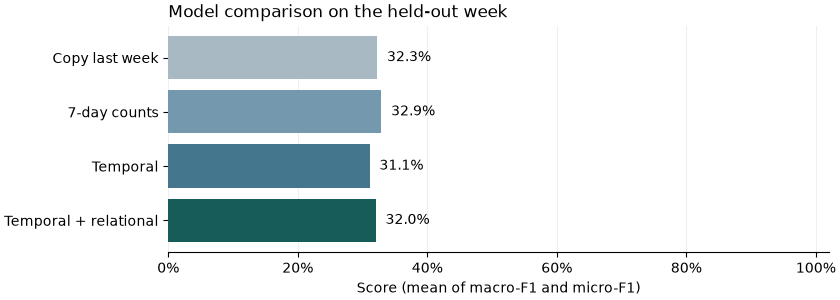

In [10]:
held_out_scores = {
    name: scores(as_submission(predicted), held_out_truth)
    for name, predicted in held_out_predictions.items()
}
metrics = pd.DataFrame({
    name: {key: result[key] for key in ("macro_f1", "micro_f1", "score")}
    for name, result in held_out_scores.items()
}).T
per_activity = pd.DataFrame({name: result["per_event"] for name, result in held_out_scores.items()}).T
display(metrics.style.format("{:.2%}"))
display(per_activity.style.format("{:.2%}"))
observed_events = [event for event in EVENT_COLS if held_out_truth[event].any()]
if 0 < len(observed_events) < len(EVENT_COLS):
    absent = [event for event in EVENT_COLS if event not in observed_events]
    print('Zero observed positives for ' + ', '.join(absent) + '. The course evaluator gives F1 = 1 when predictions and truth are both empty.')
    observed_only = pd.Series({
        name: scores(as_submission(predicted), held_out_truth, events=observed_events)["score"]
        for name, predicted in held_out_predictions.items()
    }, name="Score on activities with held-out positives")
    display(observed_only.to_frame().style.format("{:.2%}"))

time_delta = 100 * (metrics.loc["Temporal", "score"] - metrics.loc["7-day counts", "score"])
relationship_delta = 100 * (metrics.loc["Temporal + relational", "score"] - metrics.loc["Temporal", "score"])
print(f"Temporal feature change: {time_delta:+.2f} percentage points")
print(f"Relational feature change: {relationship_delta:+.2f} percentage points")

fig, ax = plt.subplots(figsize=(8.4, 3.0), layout="constrained")
positions = np.arange(len(metrics))
ax.barh(positions, metrics["score"], color=["#a8b9c4", "#7498ad", "#44778e", "#175c59"])
ax.set_yticks(positions, metrics.index)
ax.invert_yaxis()
ax.set_xlim(0, 1.02)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Score (mean of macro-F1 and micro-F1)")
ax.set_title("Model comparison on the held-out week", loc="left")
for i, score in enumerate(metrics["score"]):
    ax.text(score + 0.015, i, f"{score:.1%}", va="center")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.savefig(RESULTS / "held_out_scores.svg")
plt.show()

metrics.to_csv(RESULTS / "held_out_metrics.csv", index_label="Model")
per_activity.to_csv(RESULTS / "held_out_per_activity.csv", index_label="Model")
folds.to_csv(RESULTS / "historical_windows.csv", index=False)

## Predict the official week

Refit the full model on all completed historical folds using its tuned thresholds. Predict for the official test list in file order. The course evaluator verifies the exact header, IDs, and binary values before the final file is moved into place.

In [11]:
full_name = "Temporal + relational"
final_features = pd.concat(feature_weeks, keys=folds.index)
final_labels = pd.concat(label_weeks, keys=folds.index)
final_models = fit_models(final_features, final_labels)
test_features = snapshot(archive_end, test_users)
test_probabilities = predict_probabilities(final_models, test_features)
test_predictions = as_submission(classify(test_probabilities, thresholds_by_model[full_name]))

output_path = ROOT / f"output_{STUDENT_ID or 'predictions'}.csv"
temporary = output_path.with_suffix(".csv.part")
test_predictions.to_csv(temporary, index=False)
try:
    checked = subprocess.run([
        sys.executable, str(ROOT / "scripts" / "evaluate.py"),
        "--pred", str(temporary), "--input", str(TEST_INPUT),
    ], check=True, stdout=subprocess.PIPE, text=True)
    temporary.replace(output_path)
finally:
    temporary.unlink(missing_ok=True)
print(checked.stdout.strip())
print(f"Saved {output_path.name}")
print(f"Test users observed during the last 10 days: {test_features['any_activity_days_10d'].gt(0).sum():,}")
display(test_predictions[EVENT_COLS].sum().rename("Predicted positives").to_frame())

Format check: no errors (4465 users)
Saved output_315540018.csv
Test users observed during the last 10 days: 1,144


,Predicted positives
open_pr,479
open_issue,292
issue_comment,358
pr_review,311
pr_review_comment,63
push,20


## Schema and pipeline for the report

The schema graph includes every foreign key declared in the course preprocessor, including the self-reference in `PRReviewComments`. Its DOT source can be rendered with Graphviz. The framework figure summarizes the pipeline used by this notebook.

Saved results/schema.dot and results/framework.svg.


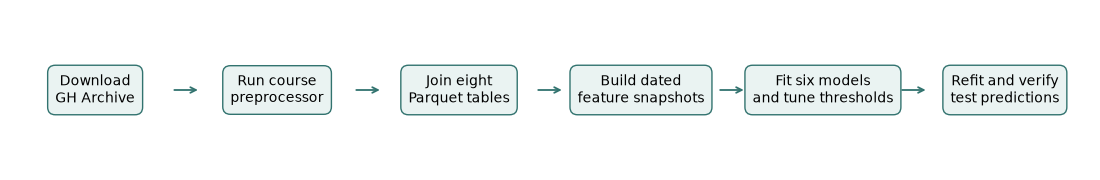

In [12]:
dot = [
    "digraph CourseSchema {",
    '  graph [rankdir=LR, splines=true];',
    '  node [shape=record, fontname="Arial"];',
]
for name, spec in TABLES.items():
    fields = [f"<{spec['pk']}> PK {spec['pk']}", *(f"<{fk}> FK {fk}" for fk in spec["fks"])]
    label = "|".join([name, *fields])
    dot.append(f'  {name} [label="{{{label}}}"];')
for name, spec in TABLES.items():
    for foreign_key, reference in spec["fks"].items():
        dot.append(f"  {name}:{foreign_key} -> {reference}:{TABLES[reference]['pk']};")
dot.append("}")
(RESULTS / "schema.dot").write_text("\n".join(dot) + "\n", encoding="utf-8")

steps = [
    "Download\nGH Archive",
    "Run course\npreprocessor",
    "Join eight\nParquet tables",
    "Build dated\nfeature snapshots",
    "Fit six models\nand tune thresholds",
    "Refit and verify\ntest predictions",
]
fig, ax = plt.subplots(figsize=(11, 1.8), layout="constrained")
ax.set(xlim=(-0.5, len(steps) - 0.5), ylim=(-0.5, 0.5))
ax.axis("off")
for i, step in enumerate(steps):
    ax.text(i, 0, step, ha="center", va="center", fontsize=10,
            bbox={"boxstyle": "round,pad=0.55", "facecolor": "#eaf3f2", "edgecolor": "#32736f"})
    if i:
        ax.annotate("", (i - 0.42, 0), (i - 0.58, 0),
                    arrowprops={"arrowstyle": "->", "color": "#32736f", "lw": 1.3})
fig.savefig(RESULTS / "framework.svg")
plt.show()
print("Saved results/schema.dot and results/framework.svg.")